In [ ]:
!pip install evaluate
!pip install torch transformers pandas scikit-learn
!pip install transformers torch sklearn pandas
!pip install --upgrade torch torchvision torchaudio transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 50.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 58.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 53.3 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling

In [ ]:
from google.colab import files
files.upload()

In [ ]:
import os
import shutil

# Crear la carpeta destino
os.makedirs("/root/.config/kaggle", exist_ok=True)

# Mover el archivo al destino correcto
shutil.move("kaggle.json", "/root/.config/kaggle/kaggle.json")

# Cambiar permisos
os.chmod("/root/.config/kaggle/kaggle.json", 600)


In [ ]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

# Descarga en una carpeta de tu proyecto
api.dataset_download_files(
    "thedevastator/tweet-sentiment-s-impact-on-stock-returns",
    unzip=True
)


Dataset URL: https://www.kaggle.com/datasets/thedevastator/tweet-sentiment-s-impact-on-stock-returns


In [ ]:
import pandas as pd
df_full = pd.read_csv("full_dataset-release.csv", index_col=False)
df_full.info()

<ipython-input-5-3191c3b53d74>:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_full = pd.read_csv("full_dataset-release.csv", index_col=False)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1395450 entries, 0 to 1395449
Data columns (total 14 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   Unnamed: 0         1102013 non-null  object 
 1   TWEET              1395398 non-null  object 
 2   STOCK              862231 non-null   object 
 3   DATE               862231 non-null   object 
 4   LAST_PRICE         862231 non-null   float64
 5   1_DAY_RETURN       862231 non-null   float64
 6   2_DAY_RETURN       862231 non-null   float64
 7   3_DAY_RETURN       862231 non-null   float64
 8   7_DAY_RETURN       862231 non-null   float64
 9   PX_VOLUME          862231 non-null   float64
 10  VOLATILITY_10D     862130 non-null   float64
 11  VOLATILITY_30D     862184 non-null   float64
 12  LSTM_POLARITY      661102 non-null   float64
 13  TEXTBLOB_POLARITY  367665 non-null   float64
dtypes: float64(10), object(4)
memory usage: 149.1+ MB


In [ ]:
df_full = df_full.dropna()
df_full = df_full.drop_duplicates()

count = df_full['STOCK'].value_counts()
perc = count/count.sum()
dstr = pd.DataFrame({"Count": count, "Percentage": perc}).reset_index()
dstr

,STOCK,Count,Percentage
0,Ford,52198,0.141989
1,Facebook,40837,0.111085
2,Google,33697,0.091663
3,Next,32606,0.088695
4,Apple,27940,0.076002
...,...,...,...
96,Volkswagen,18,0.000049
97,Equinor,12,0.000033
98,CVS Health,11,0.000030
99,21CF,4,0.000011


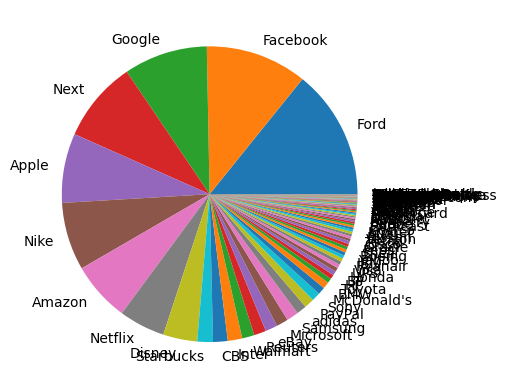

In [ ]:
import matplotlib.pyplot as plt
plt.pie(dstr['Count'], labels = dstr['STOCK'])
plt.show()

In [ ]:
# Top 5 stocks (~50% share of tweets)
TOP_STOCKS = dstr['STOCK'].head().to_list()

# Middle 25%
MID_STOCKS = dstr['STOCK'].iloc[5:].head().to_list()

# Bottom 25% (Below Starbucks)
BOT_STOCKS = dstr['STOCK'].iloc[10:].to_list()

In [ ]:
# COL = ['Ford', 'Facebook', 'Google']
df_top = df_full[df_full['STOCK'].isin(TOP_STOCKS) | df_full['TWEET'].isin(TOP_STOCKS)]
df_top = df_top.reset_index(drop=True)
l1 = len(df_top)
l2 = len(df_top[df_top['Unnamed: 0'].isnull()])
df_top[df_top['Unnamed: 0'].isnull()]
print(f"Expected cleaned df size: {l1 - l2}")

df_mid = df_full[df_full['STOCK'].isin(MID_STOCKS) | df_full['TWEET'].isin(MID_STOCKS)]
df_mid = df_mid.reset_index(drop=True)
l1 = len(df_mid)
l2 = len(df_mid[df_mid['Unnamed: 0'].isnull()])
df_mid[df_mid['Unnamed: 0'].isnull()]
print(f"Expected cleaned df size: {l1 - l2}")

df_bot = df_full[df_full['STOCK'].isin(BOT_STOCKS) | df_full['TWEET'].isin(BOT_STOCKS)]
df_bot = df_bot.reset_index(drop=True)
l1 = len(df_bot)
l2 = len(df_bot[df_bot['Unnamed: 0'].isnull()])
df_bot[df_bot['Unnamed: 0'].isnull()]
print(f"Expected cleaned df size: {l1 - l2}")

Expected cleaned df size: 187278
Expected cleaned df size: 89782
Expected cleaned df size: 90560


In [ ]:
print(df_top['STOCK'])

0         Google
1         Google
2          Apple
3           Ford
4         Google
           ...  
187273      Ford
187274    Google
187275    Google
187276      Ford
187277      Next
Name: STOCK, Length: 187278, dtype: object


In [ ]:
print(df_mid['STOCK'])

0        Starbucks
1        Starbucks
2           Amazon
3        Starbucks
4           Disney
           ...    
89777    Starbucks
89778       Amazon
89779       Disney
89780       Disney
89781       Disney
Name: STOCK, Length: 89782, dtype: object


In [ ]:
print(df_bot['STOCK'])

0         PayPal
1         PayPal
2         PayPal
3         PayPal
4        Reuters
          ...   
90555    Reuters
90556       Visa
90557      Honda
90558     PayPal
90559       Sony
Name: STOCK, Length: 90560, dtype: object


In [ ]:
misaligned_rows = df_full[df_full.iloc[:, 0].isna()]
print(f"Misaligned rows: {len(misaligned_rows)} out of {len(df_full)} total")
# before: Misaligned rows: 293437 out of 143282 total
# now weird: Misaligned rows: 0 out of 367620 total

Misaligned rows: 0 out of 367620 total


In [ ]:
# Function to fix misalignment
def fix_misalignment(df):
    # Copy the original DataFrame to avoid altering it directly
    df = df.copy()

    # Create a mask where the first column is NaN
    mask = df.iloc[:, 0].isna()

    # Iterate over rows where the mask is True
    for idx in df[mask].index.tolist():  # Use a list of indices to avoid dynamic changes
        # Get the previous row index
        previous_idx = idx - 1

        # Ensure the previous index is valid and within bounds
        if previous_idx in df.index:
            for col in range(1, len(df.columns)):
                # Check if the current value is non-NaN
                if not pd.isna(df.iloc[idx, col]):
                    # Ensure the column is within bounds of the previous row
                    if col+1 < len(df.columns):
                        df.iloc[previous_idx, col+1] = df.iloc[idx, col]

    # Drop rows where the first column is NaN
    df = df[~mask]

    return df

In [ ]:
df_full = fix_misalignment(df_full)

**Data cleaning**

In [ ]:
df_full_cleaned = df_full.reset_index(drop=True)
df_full_cleaned = df_full_cleaned.drop('Unnamed: 0', axis=1)
df_full_cleaned.head(5)

,TWEET,STOCK,DATE,LAST_PRICE,1_DAY_RETURN,2_DAY_RETURN,3_DAY_RETURN,7_DAY_RETURN,PX_VOLUME,VOLATILITY_10D,VOLATILITY_30D,LSTM_POLARITY,TEXTBLOB_POLARITY
0,@FAME95FM1 Jamaicans make money with @Payoneer...,PayPal,31/01/2017,39.78,0.002011,0.012318,0.012318,0.054801,9100057.0,18.769,16.099,-1.0,0.0
1,@CBSi Jamaicans make money with @Payoneer @Pay...,PayPal,31/01/2017,39.78,0.002011,0.012318,0.012318,0.054801,9100057.0,18.769,16.099,1.0,0.0
2,@Hitz92fm Jamaicans make money with @Payoneer ...,PayPal,31/01/2017,39.78,0.002011,0.012318,0.012318,0.054801,9100057.0,18.769,16.099,-1.0,0.0
3,"RT @nikitakhara: Thank you, @Starbucks CEO for...",Starbucks,31/01/2017,55.22,0.012314,0.016298,0.016298,0.058312,14307985.0,23.916,17.298,1.0,0.2
4,@gawker Jamaicans make money with @Payoneer @P...,PayPal,31/01/2017,39.78,0.002011,0.012318,0.012318,0.054801,9100057.0,18.769,16.099,-1.0,0.0


In [ ]:
# Dates are non-consecutive outisde of (2018-7-11 to 2018-10-2) so we'll exclude those values
df_full_cleaned['DATE'] = pd.to_datetime(df_full_cleaned['DATE'], dayfirst=True)

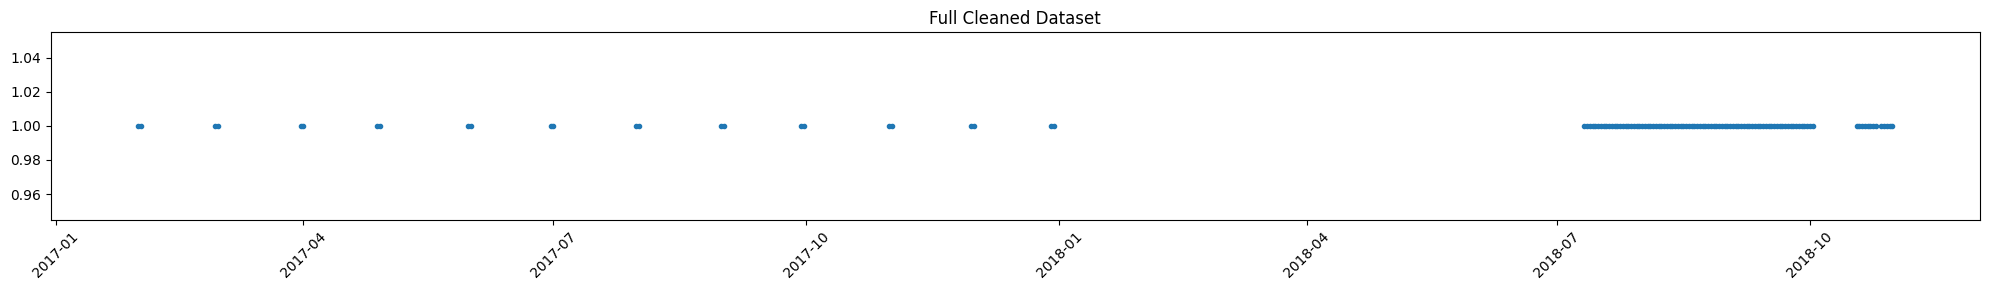

In [ ]:
# Dates seems to be non-concsecutive until 2018-7-11
# Visualize dates in the full cleaned dataset
fig, ax = plt.subplots(1, 1, figsize=(20, 3))  # Only 1 plot

dates = df_full_cleaned['DATE'].sort_values().unique()
ax.scatter(x=dates, y=[1]*len(dates), marker='.')
ax.tick_params(axis='x', rotation=45)
ax.set_title("Full Cleaned Dataset")

plt.tight_layout()
plt.show()

In [ ]:
# Function to slice dataframe to keep only dates after 2018-7-11
def slice_date(df):
    df = df[(df['DATE'] >= '2018-7-11') & (df['DATE'] <= '2018-10-2')].sort_values(by='DATE')
    df = df.reset_index(drop=True)
    return df

df_full_cleaned = slice_date(df_full_cleaned)

In [ ]:
print(df_full_cleaned['STOCK'].unique())

['Apple' 'Netflix' 'Nike' 'Google' 'Kroger' 'HP' 'Disney' 'Next' 'Yahoo'
 'Starbucks' 'Samsung' 'Ford' 'BMW' 'Comcast' 'PayPal' 'Amazon' 'adidas'
 'Facebook' 'Intel' 'Pfizer' 'Walmart' 'BP' 'Verizon' 'eBay' "McDonald's"
 'Ryanair' 'Microsoft' 'Toyota' 'Sony' 'Costco' 'Heineken' 'CBS' 'Honda'
 'Audi' 'Cisco' 'FedEx' 'Reuters' 'Burberry' 'Mastercard' 'IBM' 'Exxon'
 'Gillette' 'Visa' 'Nestle' 'UPS' 'BASF' 'Chevron' 'Siemens' 'ASOS' 'SAP'
 'Pepsi' 'Groupon' 'Nissan' 'Shell' 'Hyundai' 'Tesco' 'Colgate' 'Adobe'
 'Allianz' 'AstraZeneca' 'Vodafone' 'Oracle' 'Bayer' 'Santander'
 'Citigroup' "Kellogg's" 'TripAdvisor' 'JPMorgan' 'CocaCola' 'Boeing'
 'HSBC' 'Carrefour' 'GSK' 'BlackRock' 'Thales' 'Aviva' 'Expedia' 'TMobile'
 'easyJet' 'Danone' 'Viacom' "L'Oreal" 'Equinor' '21CF' 'AT&T'
 'bookingcom' 'Home Depot' 'Morgan Stanley' 'American Express'
 'Bank of America' 'Deutsche Bank' 'Goldman Sachs' 'Wells Fargo'
 'Volkswagen' 'salesforce.com' 'H&M' 'General Electric' 'John Deere' 'P&G'
 'Cardinal He

In [ ]:
df_full_cleaned.to_csv('df_full_cleaned.csv', index=False)

In [ ]:
print(df_full_cleaned.shape)
print(df_full_cleaned.columns)
# shape: (280785, 13)

(280785, 13)
Index(['TWEET', 'STOCK', 'DATE', 'LAST_PRICE', '1_DAY_RETURN', '2_DAY_RETURN',
       '3_DAY_RETURN', '7_DAY_RETURN', 'PX_VOLUME', 'VOLATILITY_10D',
       'VOLATILITY_30D', 'LSTM_POLARITY', 'TEXTBLOB_POLARITY'],
      dtype='object')


In [ ]:
def group_df(df):
    df_grouped = df.groupby(['STOCK', 'DATE'], as_index=False).agg({'LSTM_POLARITY':'sum', '1_DAY_RETURN':'mean', 'PX_VOLUME':'mean', 'VOLATILITY_10D':'mean'}).reset_index(drop=True)
    return df_grouped

In [ ]:
df_full_final = group_df(df_full_cleaned)

In [ ]:
print(df_full_final.shape)
print(df_full_final.head())
print(df_full_final.columns)
# cols: STOCK DATE  LSTM_POLARITY  1_DAY_RETURN  PX_VOLUME  VOLATILITY_10D

(5734, 6)
  STOCK       DATE  LSTM_POLARITY  1_DAY_RETURN  PX_VOLUME  VOLATILITY_10D
0  21CF 2018-08-10            1.0      0.002639  5206734.0           7.018
1  21CF 2018-09-05            0.0      0.001547  7801635.0           6.489
2  ASOS 2018-07-11           -1.0      0.008923   217525.0          24.907
3  ASOS 2018-07-15           -2.0      0.000000   846417.0          67.943
4  ASOS 2018-07-17           -1.0     -0.045575   678881.0          72.684
Index(['STOCK', 'DATE', 'LSTM_POLARITY', '1_DAY_RETURN', 'PX_VOLUME',
       'VOLATILITY_10D'],
      dtype='object')


In [ ]:
# Fix misalighments on top, mid, bot stocks
df_bot_cleaned = fix_misalignment(df_bot)
df_mid_cleaned = fix_misalignment(df_mid)
df_top_cleaned = fix_misalignment(df_top)

In [ ]:

df_top_cleaned = df_top.reset_index(drop=True)
df_top_cleaned = df_top.drop('Unnamed: 0', axis=1)
df_top_cleaned.head(5)

,TWEET,STOCK,DATE,LAST_PRICE,1_DAY_RETURN,2_DAY_RETURN,3_DAY_RETURN,7_DAY_RETURN,PX_VOLUME,VOLATILITY_10D,VOLATILITY_30D,LSTM_POLARITY,TEXTBLOB_POLARITY
0,RT @IndiaHistorypic: 1994::Young @sundarpichai...,Google,31/01/2017,820.19,0.004438,0.030286,0.030286,0.035772,2020180.0,21.549,14.953,-1.0,0.00
1,"RT @Google: ""If you have the feeling that some...",Google,31/01/2017,820.19,0.004438,0.030286,0.030286,0.035772,2020180.0,21.549,14.953,-1.0,-0.55
2,"RT @IBMWatson: Welcome @Apple, #ACLU, #AAAI, @...",Apple,31/01/2017,121.35,0.002307,0.004944,0.004944,-0.011372,49200993.0,9.114,8.417,1.0,1.00
3,RT @ColMorrisDavis: My family owned a @Ford de...,Ford,31/01/2017,12.36,0.000809,0.010518,0.010518,0.020227,46974479.0,26.321,27.647,1.0,0.00
4,RT @ThatBitchFromNJ: Google's sponsored ad for...,Google,31/01/2017,820.19,0.004438,0.030286,0.030286,0.035772,2020180.0,21.549,14.953,-1.0,-0.10


In [ ]:
df_mid_cleaned = df_mid_cleaned.reset_index(drop=True)
df_mid_cleaned = df_mid_cleaned.drop('Unnamed: 0', axis=1)
df_mid_cleaned.head(5)

,TWEET,STOCK,DATE,LAST_PRICE,1_DAY_RETURN,2_DAY_RETURN,3_DAY_RETURN,7_DAY_RETURN,PX_VOLUME,VOLATILITY_10D,VOLATILITY_30D,LSTM_POLARITY,TEXTBLOB_POLARITY
0,"RT @nikitakhara: Thank you, @Starbucks CEO for...",Starbucks,31/01/2017,55.22,0.012314,0.016298,0.016298,0.058312,14307985.0,23.916,17.298,1.0,0.20
1,RT @cultcommoncore: Dumping @Starbucks\r\r\r\r...,Starbucks,31/01/2017,55.22,0.012314,0.016298,0.016298,0.058312,14307985.0,23.916,17.298,-1.0,0.00
2,@amazon has your back when it comes to food sh...,Amazon,31/01/2017,823.48,0.008379,0.014924,0.014924,-0.001263,3137196.0,13.447,16.992,-1.0,0.00
3,"RT @nia4_trump: So instead of hiring 10,000 un...",Starbucks,31/01/2017,55.22,0.012314,0.016298,0.016298,0.058312,14307985.0,23.916,17.298,-1.0,0.00
4,Hmmm interesting... \r\r\r\r\r\r\nonly @IBM ha...,Disney,31/01/2017,110.65,0.002621,-0.012201,-0.012201,-0.024853,8485838.0,12.229,12.982,-1.0,0.25


In [ ]:
df_bot_cleaned = df_bot_cleaned.reset_index(drop=True)
df_bot_cleaned = df_bot_cleaned.drop('Unnamed: 0', axis=1)
df_bot_cleaned.head(5)

,TWEET,STOCK,DATE,LAST_PRICE,1_DAY_RETURN,2_DAY_RETURN,3_DAY_RETURN,7_DAY_RETURN,PX_VOLUME,VOLATILITY_10D,VOLATILITY_30D,LSTM_POLARITY,TEXTBLOB_POLARITY
0,@FAME95FM1 Jamaicans make money with @Payoneer...,PayPal,31/01/2017,39.7800,0.002011,0.012318,0.012318,0.054801,9100057.0,18.769,16.099,-1.0,0.0
1,@CBSi Jamaicans make money with @Payoneer @Pay...,PayPal,31/01/2017,39.7800,0.002011,0.012318,0.012318,0.054801,9100057.0,18.769,16.099,1.0,0.0
2,@Hitz92fm Jamaicans make money with @Payoneer ...,PayPal,31/01/2017,39.7800,0.002011,0.012318,0.012318,0.054801,9100057.0,18.769,16.099,-1.0,0.0
3,@gawker Jamaicans make money with @Payoneer @P...,PayPal,31/01/2017,39.7800,0.002011,0.012318,0.012318,0.054801,9100057.0,18.769,16.099,-1.0,0.0
4,@Dal_Schnur @DKuzLA @wrightco0704 @psuba98 @Re...,Reuters,31/01/2017,49.3887,-0.002677,0.003122,0.003122,0.004461,547029.0,9.665,9.094,1.0,0.0


In [ ]:
# Dates are non-consecutive outisde of (2018-7-11 to 2018-10-2) so we'll exclude those values
df_top_cleaned['DATE'] = pd.to_datetime(df_top_cleaned['DATE'], dayfirst=True)
df_mid_cleaned['DATE'] = pd.to_datetime(df_mid_cleaned['DATE'], dayfirst=True)
df_bot_cleaned['DATE'] = pd.to_datetime(df_bot_cleaned['DATE'], dayfirst=True)

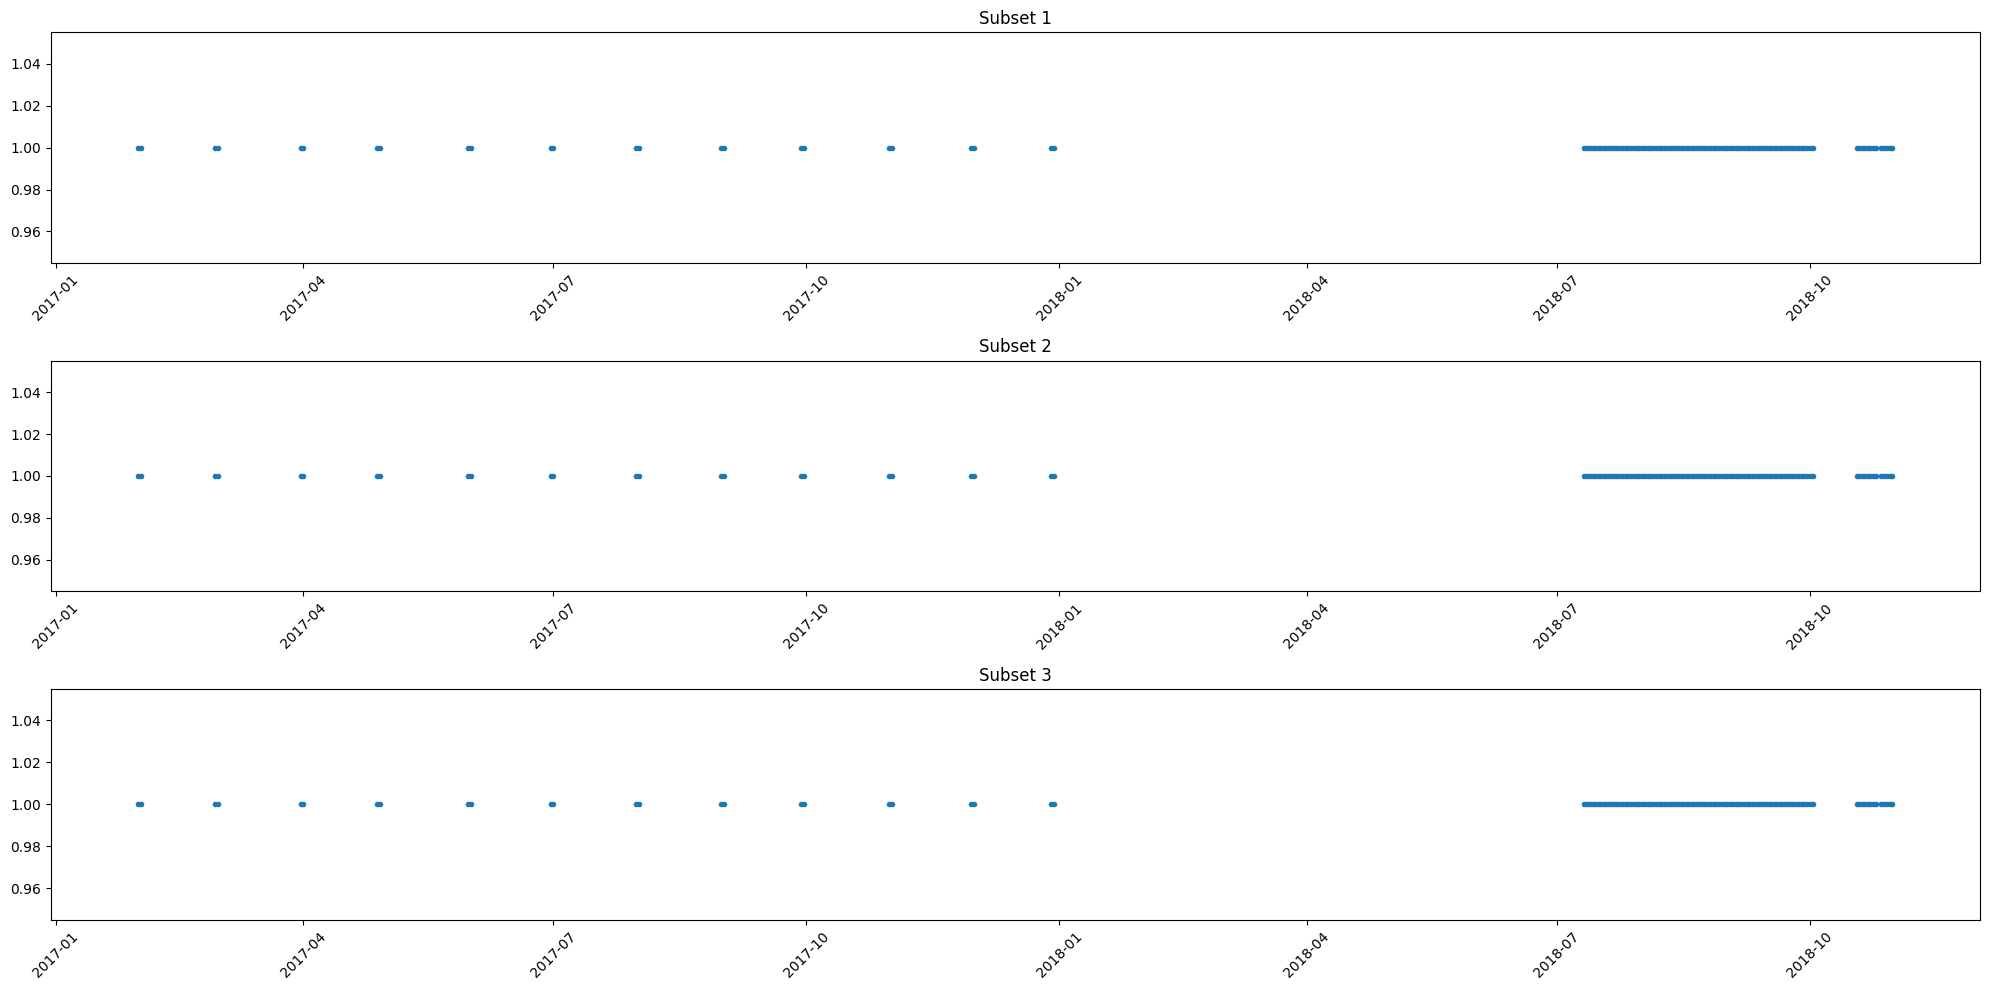

In [ ]:
# Dates seems to be non-concsecutive until 2018-7-11
fig, ax, = plt.subplots(3, 1, figsize=(20, 10))
id=0
for df in [df_top_cleaned, df_mid_cleaned, df_bot_cleaned]:
    dates = df['DATE'].sort_values().unique()
    ax[id].scatter(x=dates, y=[1]*len(dates), marker='.')
    ax[id].tick_params(axis='x', rotation=45)
    ax[id].set_title(f"Subset {id + 1}")
    id += 1
plt.tight_layout()
plt.show()

In [ ]:
# Function to slice dataframe to keep only dates after 2018-7-11
def slice_date(df):
    df = df[(df['DATE'] >= '2018-7-11') & (df['DATE'] <= '2018-10-2')].sort_values(by='DATE')
    df = df.reset_index(drop=True)
    return df

df_top_cleaned = slice_date(df_top_cleaned)
df_mid_cleaned = slice_date(df_mid_cleaned)
df_bot_cleaned = slice_date(df_bot_cleaned)

In [ ]:
print(df_top_cleaned.shape)
print(df_mid_cleaned.shape)
print(df_bot_cleaned.shape)
print(df_top_cleaned.columns)

(148883, 13)
(71025, 13)
(60877, 13)
Index(['TWEET', 'STOCK', 'DATE', 'LAST_PRICE', '1_DAY_RETURN', '2_DAY_RETURN',
       '3_DAY_RETURN', '7_DAY_RETURN', 'PX_VOLUME', 'VOLATILITY_10D',
       'VOLATILITY_30D', 'LSTM_POLARITY', 'TEXTBLOB_POLARITY'],
      dtype='object')


In [ ]:
# Save cleaned versions of top, bot, mid stocks
df_top_cleaned.to_csv('df_top_cleaned.csv', index=False)
df_mid_cleaned.to_csv('df_mid_cleaned.csv', index=False)
df_bot_cleaned.to_csv('df_bot_cleaned.csv', index=False)

In [ ]:
print(df_top_cleaned.isnull().sum())
print(df_mid_cleaned.isnull().sum())
print(df_bot_cleaned.isnull().sum())
df_bot_cleaned = df_bot_cleaned.dropna() # ok since we're only dropping 1 row

TWEET                0
STOCK                0
DATE                 0
LAST_PRICE           0
1_DAY_RETURN         0
2_DAY_RETURN         0
3_DAY_RETURN         0
7_DAY_RETURN         0
PX_VOLUME            0
VOLATILITY_10D       0
VOLATILITY_30D       0
LSTM_POLARITY        0
TEXTBLOB_POLARITY    0
dtype: int64
TWEET                0
STOCK                0
DATE                 0
LAST_PRICE           0
1_DAY_RETURN         0
2_DAY_RETURN         0
3_DAY_RETURN         0
7_DAY_RETURN         0
PX_VOLUME            0
VOLATILITY_10D       0
VOLATILITY_30D       0
LSTM_POLARITY        0
TEXTBLOB_POLARITY    0
dtype: int64
TWEET                0
STOCK                0
DATE                 0
LAST_PRICE           0
1_DAY_RETURN         0
2_DAY_RETURN         0
3_DAY_RETURN         0
7_DAY_RETURN         0
PX_VOLUME            0
VOLATILITY_10D       0
VOLATILITY_30D       0
LSTM_POLARITY        0
TEXTBLOB_POLARITY    0
dtype: int64


In [ ]:
print(df_top_cleaned['STOCK'].unique())
print(df_mid_cleaned['STOCK'].unique())
print(df_bot_cleaned['STOCK'].unique())

['Google' 'Facebook' 'Ford' 'Apple' 'Next']
['Amazon' 'Netflix' 'Nike' 'Disney' 'Starbucks']
['Visa' 'BMW' 'Comcast' 'PayPal' 'adidas' 'Microsoft' 'HP' 'Yahoo'
 'Samsung' 'Pfizer' 'Kroger' 'Ryanair' 'Verizon' 'eBay' "McDonald's"
 'Toyota' 'Walmart' 'BP' 'Sony' 'Intel' 'Cisco' 'CBS' 'Honda' 'Costco'
 'FedEx' 'Reuters' 'Burberry' 'Mastercard' 'IBM' 'Exxon' 'Gillette' 'Audi'
 'Heineken' 'Nestle' 'UPS' 'Siemens' 'BASF' 'Chevron' 'SAP' 'ASOS' 'Pepsi'
 'Nissan' 'Groupon' 'Shell' 'Hyundai' 'Colgate' 'Tesco' 'Adobe' 'Allianz'
 'Citigroup' 'Oracle' 'Bayer' "Kellogg's" 'Carrefour' 'Santander'
 'TripAdvisor' 'JPMorgan' 'CocaCola' 'Vodafone' 'Boeing' 'HSBC'
 'AstraZeneca' 'GSK' 'BlackRock' 'Thales' 'Aviva' 'Expedia' 'TMobile'
 'easyJet' 'Danone' 'Viacom' "L'Oreal" 'Equinor' '21CF' 'AT&T'
 'Bank of America' 'American Express' 'Home Depot' 'bookingcom'
 'Morgan Stanley' 'salesforce.com' 'Volkswagen' 'Goldman Sachs'
 'Deutsche Bank' 'Wells Fargo' 'H&M' 'General Electric' 'P&G' 'John Deere'
 'Cardinal

In [ ]:
df_top_final = group_df(df_top_cleaned)
df_mid_final = group_df(df_mid_cleaned)
df_bot_final = group_df(df_bot_cleaned)

In [ ]:
print(df_top_final.shape)
print(df_mid_final.shape)
print(df_bot_final.shape)
print(df_top_final.head())
print(df_mid_final.head())
print(df_bot_final.head())

(420, 6)
(420, 6)
(4894, 6)
   STOCK       DATE  LSTM_POLARITY  1_DAY_RETURN   PX_VOLUME  VOLATILITY_10D
0  Apple 2018-07-11           77.0      0.013147  18831470.0          18.568
1  Apple 2018-07-12           61.0     -0.016490  18041131.0          20.021
2  Apple 2018-07-13            2.0     -0.001568  12519792.0          19.797
3  Apple 2018-07-14           -5.0      0.000000  12519792.0          19.797
4  Apple 2018-07-15          -19.0      0.000000  12519792.0          19.797
    STOCK       DATE  LSTM_POLARITY  1_DAY_RETURN  PX_VOLUME  VOLATILITY_10D
0  Amazon 2018-07-11           35.0     -0.006798  3209782.0          16.439
1  Amazon 2018-07-12            7.0     -0.023166  4532743.0          16.113
2  Amazon 2018-07-13            0.0     -0.009051  4386679.0          15.588
3  Amazon 2018-07-14           -1.0      0.000000  4386679.0          15.588
4  Amazon 2018-07-15            4.0      0.000000  4386679.0          15.588
  STOCK       DATE  LSTM_POLARITY  1_DAY_RETURN 

**FinBERT Implementation**

In [ ]:
# 1. IMPORTS Y CONFIG
import os, time, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
from collections import Counter
from tqdm import tqdm

In [ ]:
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [ ]:
# 2. CARGA (o crea) DATA
try:
    df = df_full_cleaned.copy()
except NameError:
    print("⚠️  df_full_cleaned no encontrado: creo un ejemplo mínimo.")
    data = {
        'TWEET': ["El mercado sube", "Caen acciones", "Fed optimista"]*200,
        'LSTM_POLARITY': np.random.rand(600)*2-1,
        'PX_VOLUME': np.random.randint(1e6,1e7,600),
        'VOLATILITY_30D': np.random.rand(600)*.1,
        '7_DAY_RETURN': np.random.randn(600)*.03
    }
    df = pd.DataFrame(data)

df['TARGET'] = (df['7_DAY_RETURN']>0).astype(int)
print("Distribución de clases:", Counter(df['TARGET']))

train_df, temp_df = train_test_split(df, test_size=.3, random_state=42, stratify=df['TARGET'])
val_df,   test_df = train_test_split(temp_df, test_size=.5, random_state=42, stratify=temp_df['TARGET'])

Distribución de clases: Counter({0: 145170, 1: 135615})


In [ ]:
# 3. TOKENIZER Y FEATURES NUMÉRICAS
MODEL_NAME = "yiyanghkust/finbert-tone"
tokenizer   = AutoTokenizer.from_pretrained(MODEL_NAME)

scaler = StandardScaler()
num_cols = ['LSTM_POLARITY','PX_VOLUME','VOLATILITY_30D']
train_num = scaler.fit_transform(train_df[num_cols])
val_num   = scaler.transform(val_df[num_cols])
test_num  = scaler.transform(test_df[num_cols])

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/533 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

In [ ]:
# 4. DATASET
class FinDataset(Dataset):
    def __init__(self,texts,num_feats,labels,tokenizer,max_len=64):
        self.texts, self.num_feats, self.labels = texts, num_feats, labels
        self.tok, self.max_len = tokenizer, max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        enc = self.tok(self.texts[idx],
                      truncation=True, padding='max_length',
                      max_length=self.max_len, return_tensors='pt')
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item['numeric'] = torch.tensor(self.num_feats[idx], dtype=torch.float)
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.float)
        item['index'] = torch.tensor(idx)  # ✅ Aquí añades el índice
        return item


train_ds = FinDataset(train_df.TWEET.values,train_num,train_df.TARGET.values,tokenizer)
val_ds   = FinDataset(val_df.TWEET.values,  val_num,  val_df.TARGET.values,  tokenizer)
test_ds  = FinDataset(test_df.TWEET.values, test_num, test_df.TARGET.values, tokenizer)

BATCH=64
train_dl = DataLoader(train_ds,BATCH,shuffle=True,num_workers=2,pin_memory=True)
val_dl   = DataLoader(val_ds,BATCH,num_workers=2,pin_memory=True)
test_dl  = DataLoader(test_ds,BATCH,num_workers=2,pin_memory=True)

def run_epoch(dl,train=True):
    model.train() if train else model.eval()
    tot_loss, preds, gts = 0, [], []
    loop = tqdm(dl,leave=False)
    with torch.set_grad_enabled(train):
        for batch in loop:
            ids = batch['input_ids'].to(device)
            mask= batch['attention_mask'].to(device)
            num = batch['numeric'].to(device)
            y   = batch['labels'].to(device)
            optimizer.zero_grad() if train else None
            with torch.cuda.amp.autocast():
                logits = model(ids,mask,num)
                loss = criterion(logits,y)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            tot_loss += loss.item()*len(y)
            preds.extend((torch.sigmoid(logits)>0.5).int().cpu().numpy())
            gts.extend(y.int().cpu().numpy())
    acc = accuracy_score(gts,preds)
    f1  = f1_score(gts,preds)
    return tot_loss/len(dl.dataset), acc, f1

In [ ]:
# --- FINBERT + LSTM ---
class FinBERT_LSTM(nn.Module):
    def __init__(self, model_name, lstm_hidden_dim=128, num_numeric=3, freeze_bert=True):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        if freeze_bert:
            for p in self.bert.parameters():
                p.requires_grad = False
        self.lstm = nn.LSTM(input_size=self.bert.config.hidden_size,
                            hidden_size=lstm_hidden_dim,
                            batch_first=True)
        self.numeric_fc = nn.Sequential(
            nn.Linear(num_numeric,64),
            nn.ReLU(),
            nn.Dropout(0.1)
        )
        self.classifier = nn.Linear(lstm_hidden_dim + 64,1)
    def forward(self, input_ids, attention_mask, numeric):
        bert_outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        seq_out = bert_outputs.last_hidden_state
        lstm_out, (h_n, _) = self.lstm(seq_out)
        lstm_feat = h_n[-1]
        num_feat = self.numeric_fc(numeric)
        x = torch.cat([lstm_feat, num_feat], dim=1)
        logits = self.classifier(x)
        return logits.view(-1)

# --- FINBERT CLÁSICO ---
class FinBERTClassifier(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        hid = self.bert.config.hidden_size
        self.classifier = nn.Linear(hid,1)
    def forward(self, input_ids, attention_mask, numeric=None):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls = out.last_hidden_state[:,0,:]
        logits = self.classifier(cls)
        return logits.view(-1)

# 5. MODELO HÍBRIDO: FinBERT congelado + numéricas
class HybridFinBERT(nn.Module):
    def __init__(self,model_name,freeze=True,num_numeric=3):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        if freeze:
            for p in self.bert.parameters(): p.requires_grad=False
        hid = self.bert.config.hidden_size          # 768
        self.numeric_fc = nn.Sequential(
            nn.Linear(num_numeric,64),
            nn.ReLU(),
            nn.Dropout(.1)
        )
        self.classifier = nn.Linear(hid+64,1)
    def forward(self,input_ids,attention_mask,numeric):
        out = self.bert(input_ids=input_ids,attention_mask=attention_mask)
        cls = out.last_hidden_state[:,0,:]          # [batch,768]
        num = self.numeric_fc(numeric)              # [batch,64]
        x = torch.cat([cls,num],dim=1)              # [batch,832]
        return self.classifier(x).view(-1)


In [ ]:
model = FinBERT_LSTM(MODEL_NAME).to(device)

# 6. ENTRENAMIENTO (fp16)
EPOCHS= 10
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4)
criterion = nn.BCEWithLogitsLoss()
scaler = torch.cuda.amp.GradScaler()

best_f1=0
for ep in range(1, EPOCHS+1):
    tr_loss, tr_acc, tr_f1 = run_epoch(train_dl, train=True)
    vl_loss, vl_acc, vl_f1 = run_epoch(val_dl, train =False)
    print(f"🟢 Epoch {ep}/{EPOCHS} | Train loss {tr_loss:.4f} F1 {tr_f1:.3f} | Val loss {vl_loss:.4f} F1 {vl_f1:.3f}")
    if vl_f1 > best_f1:
        best_f1 = vl_f1
        torch.save(model.state_dict(), "best_finbert_lstm_model.pt")

# 7. TEST FINAL
model.load_state_dict(torch.load("best_finbert_lstm_model.pt"))
_, tst_acc, tst_f1 = run_epoch(test_dl, train=False)
print(f"\n🎯 TEST | Accuracy {tst_acc:.3f} | F1 {tst_f1:.3f}")

pytorch_model.bin:   0%|          | 0.00/439M [00:00<?, ?B/s]

<ipython-input-45-5af075de66b5>:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
  0%|          | 0/3072 [00:00<?, ?it/s]<ipython-input-43-68929bc809fc>:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


model.safetensors:   0%|          | 0.00/439M [00:00<?, ?B/s]

  0%|          | 0/659 [00:00<?, ?it/s]<ipython-input-43-68929bc809fc>:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


🟢 Epoch 1/10 | Train loss 0.6160 F1 0.589 | Val loss 0.5589 F1 0.679


...

🟢 Epoch 9/10 | Train loss 0.4193 F1 0.774 | Val loss 0.4710 F1 0.732


  0%|          | 0/3072 [00:00<?, ?it/s]<ipython-input-43-68929bc809fc>:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
  0%|          | 0/659 [00:00<?, ?it/s]<ipython-input-43-68929bc809fc>:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


🟢 Epoch 10/10 | Train loss 0.4088 F1 0.783 | Val loss 0.4794 F1 0.723


  0%|          | 0/659 [00:00<?, ?it/s]<ipython-input-43-68929bc809fc>:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
                                                 


🎯 TEST | Accuracy 0.742 | F1 0.740


In [ ]:
# Cambia aquí para probar uno u otro:
model = FinBERTClassifier(MODEL_NAME).to(device)

# 6. ENTRENAMIENTO (fp16)
EPOCHS= 10
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4)
criterion = nn.BCEWithLogitsLoss()
scaler = torch.cuda.amp.GradScaler()

best_f1=0
for ep in range(1, EPOCHS+1):
    tr_loss, tr_acc, tr_f1 = run_epoch(train_dl, train=True)
    vl_loss, vl_acc, vl_f1 = run_epoch(val_dl, train=False)
    print(f"🟢 Epoch {ep}/{EPOCHS} | Train loss {tr_loss:.4f} F1 {tr_f1:.3f} | Val loss {vl_loss:.4f} F1 {vl_f1:.3f}")
    if vl_f1 > best_f1:
        best_f1 = vl_f1
        torch.save(model.state_dict(), "best_finbert_model.pt")

# 7. TEST FINAL
model.load_state_dict(torch.load("best_finbert_model.pt"))
_, tst_acc, tst_f1 = run_epoch(test_dl, train=False)
print(f"\n🎯 TEST | Accuracy {tst_acc:.3f} | F1 {tst_f1:.3f}")

In [ ]:
model = HybridFinBERT(MODEL_NAME,freeze=True).to(device)

# 6. ENTRENAMIENTO (fp16)
EPOCHS= 10
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4)
criterion = nn.BCEWithLogitsLoss()
scaler = torch.cuda.amp.GradScaler()


best_f1=0
for ep in range(1,EPOCHS+1):
    tr_loss, tr_acc, tr_f1 = run_epoch(train_dl,train=True)
    vl_loss, vl_acc, vl_f1 = run_epoch(val_dl,train=False)
    print(f"🟢 Epoch {ep}/{EPOCHS} | "
          f"Train loss {tr_loss:.4f} F1 {tr_f1:.3f} | "
          f"Val loss {vl_loss:.4f} F1 {vl_f1:.3f}")
    if vl_f1>best_f1:
        best_f1=vl_f1
        torch.save(model.state_dict(),"best_hybrid_finbert.pt")

# 7. TEST FINAL
model.load_state_dict(torch.load("best_hybrid_finbert.pt"))
_, tst_acc, tst_f1 = run_epoch(test_dl,train=False)
print(f"\n🎯 TEST | Accuracy {tst_acc:.3f} | F1 {tst_f1:.3f}")

In [ ]:
import torch
import pandas as pd
from tqdm import tqdm

def predict_model(model, dataloader, device='cuda'):
    model.eval()
    model.to(device)

    all_preds = []
    all_indices = []

    with torch.no_grad():
        for batch in tqdm(dataloader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            numeric = batch['numeric'].to(device) if 'numeric' in batch else None
            indices = batch['index'].cpu().numpy()

            if numeric is not None:
                logits = model(input_ids=input_ids, attention_mask=attention_mask, numeric=numeric)
            else:
                logits = model(input_ids=input_ids, attention_mask=attention_mask)

            probs = torch.sigmoid(logits).cpu().numpy()
            preds = (probs > 0.5).astype(int)

            all_preds.extend(preds)
            all_indices.extend(indices)

    return pd.DataFrame({'original_index': all_indices, 'predicted_7_day_target': all_preds})


In [ ]:
model = HybridFinBERT(MODEL_NAME) # change model
# Cargar los pesos entrenados si tienes:
# model.load_state_dict(torch.load("ruta_al_modelo.pt"))

df_predictions = predict_model(model, test_dl)


100%|██████████| 659/659 [02:24<00:00,  4.56it/s]


In [ ]:
df_predictions.to_csv("finbert_predictions.csv", index=False)

In [ ]:
# Aseguramos que df_predictions tenga el índice original para hacer el join
df_predictions["original_index"] = test_df.index  # o el índice correcto del split usado

# Unimos con el dataframe completo (eliminamos columnas irrelevantes si quieres)
df_combined_results = df_predictions.set_index("original_index").join(
    df_full_cleaned.drop(columns=['TWEET', 'LSTM_POLARITY'], errors='ignore')
)

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Simulación de datos si no existen
try:
    df_full_cleaned
except NameError:
    print("[INFO] Creating dummy df_full_cleaned for demonstration.")
    data = {
        'COMPANY': ['Apple', 'Tesla', 'Google', 'Tesla', 'Apple'],
        'TWEET': ["Tweet 1", "Tweet 2", "Tweet 3", "Tweet 4", "Tweet 5"],
        'LSTM_POLARITY': np.random.rand(5),
        '7_DAY_RETURN': np.array([0.01, -0.02, 0.03, -0.01, 0.005]),
        'PX_VOLUME': np.random.randint(1000, 10000, 5),
        'VOLATILITY_10D': np.random.rand(5) * 0.01,
        '1_DAY_RETURN': np.array([0.002, -0.005, 0.01, 0.001, -0.003]),
        '2_DAY_RETURN': np.array([0.005, -0.01, 0.02, 0.00, -0.006]),
        '3_DAY_RETURN': np.array([0.008, -0.015, 0.025, -0.002, -0.008]),
    }
    df_full_cleaned = pd.DataFrame(data)

# Simulación de predicciones
df_validation_results = pd.DataFrame({
    'original_index': df_full_cleaned.index.tolist(),
    'actual_7_day_return': df_full_cleaned['7_DAY_RETURN'].tolist(),
    'predicted_7_day_target': (np.random.rand(len(df_full_cleaned)) > 0.5).astype(int)
})

# Unir con el dataframe original
df_combined_results = df_validation_results.set_index('original_index').join(
    df_full_cleaned.drop(columns=['TWEET', 'LSTM_POLARITY', 'PX_VOLUME', 'VOLATILITY_10D'])
)

# Periodos de retorno a evaluar
return_periods = [1, 2, 3, 7]

print("\n=== Global Accuracy and F1-score ===")
for days in return_periods:
    return_col = f'{days}_DAY_RETURN'

    if return_col in df_combined_results.columns:
        df_combined_results[f'actual_{days}d_target'] = (df_combined_results[return_col] > 0).astype(int)
        acc = accuracy_score(df_combined_results[f'actual_{days}d_target'], df_combined_results['predicted_7_day_target'])
        f1 = f1_score(df_combined_results[f'actual_{days}d_target'], df_combined_results['predicted_7_day_target'])
        print(f"{days}-Day Return → Accuracy: {acc:.4f} | F1-Score: {f1:.4f}")

print("\n=== Top 5 Companies by F1-score for Each Return Period ===")
for days in return_periods:
    return_col = f'{days}_DAY_RETURN'
    target_col = f'actual_{days}d_target'

    if target_col not in df_combined_results.columns:
        print(f"Skipping {days}-day return (no data).")
        continue

    company_stats = []

    for company, group in df_combined_results.groupby('STOCK'):
        actual = group[target_col]
        predicted = group['predicted_7_day_target']

        if len(actual.unique()) < 2:
            continue  # No clases suficientes para evaluar

        acc = accuracy_score(actual, predicted)
        f1 = f1_score(actual, predicted)
        company_stats.append({
            'STOCK': company,
            'Accuracy': acc,
            'F1_Score': f1,
            'Samples': len(group)
        })

    df_company = pd.DataFrame(company_stats).sort_values(by='F1_Score', ascending=False)

    print(f"\nTop 5 STOCK - {days}-Day Return:")
    if not df_company.empty:
        print(df_company.head(5).to_string(index=False))
    else:
        print("Insufficient data.")



=== Global Accuracy and F1-score ===
1-Day Return → Accuracy: 0.5010 | F1-Score: 0.4058
2-Day Return → Accuracy: 0.4996 | F1-Score: 0.4498
3-Day Return → Accuracy: 0.4994 | F1-Score: 0.4849
7-Day Return → Accuracy: 0.5003 | F1-Score: 0.4902

=== Top 5 Companies by F1-score for Each Return Period ===

Top 5 STOCK - 1-Day Return:
      STOCK  Accuracy  F1_Score  Samples
 CVS Health  0.714286  0.666667        7
    Equinor  0.555556  0.600000        9
 Mastercard  0.544643  0.583106      336
Wells Fargo  0.600000  0.578947       40
   Vodafone  0.533569  0.507463      283

Top 5 STOCK - 2-Day Return:
      STOCK  Accuracy  F1_Score  Samples
 CVS Health  0.714286  0.750000        7
       21CF  0.666667  0.666667        3
        P&G  0.636364  0.600000       11
 John Deere  0.727273  0.571429       11
TripAdvisor  0.549296  0.567568      142

Top 5 STOCK - 3-Day Return:
         STOCK  Accuracy  F1_Score  Samples
    CVS Health  0.857143  0.857143        7
           P&G  0.727273  0.727